In [1]:

import numpy as np
import matplotlib.pyplot as plt

from dataclasses import dataclass

C_LIGHT = 299792458.0


@dataclass(frozen=True)
class MirrorMemory:
    """
    Simplified free-space multipass optical quantum memory.

    R          : intensity reflectivity per mirror reflection
    eta_in     : injection efficiency
    eta_out    : extraction efficiency
    path_m     : optical path length between reflections (meters)
    phase_rad  : phase accumulated per reflection (radians)
    """

    R: float = 0.9999
    eta_in: float = 0.99
    eta_out: float = 0.99
    path_m: float = 1.0
    phase_rad: float = 0.0

    def __post_init__(self):
        for name in ("R", "eta_in", "eta_out"):
            value = getattr(self, name)
            if not 0.0 <= value <= 1.0:
                raise ValueError(f"{name} must be between 0 and 1")

        if self.path_m <= 0:
            raise ValueError("path_m must be positive")

    def efficiency(self, N):
        """Total intensity transmissivity after N reflections."""
        N = np.asarray(N)
        if np.any(N < 0) or np.any(N != np.floor(N)):
            raise ValueError("N must contain nonnegative integers")

        return self.eta_in * self.eta_out * self.R**N

    def storage_time_us(self, N):
        """Storage duration in microseconds."""
        return np.asarray(N) * self.path_m / C_LIGHT * 1e6

    def phase(self, N):
        """Deterministic phase shift after N reflections."""
        return np.asarray(N) * self.phase_rad

    def amplitude(self, N):
        """Complex amplitude survival coefficient."""
        return np.sqrt(self.efficiency(N)) * np.exp(
            1j * self.phase(N)
        )


# ----------------------------------------------------------
# Unit tests
# ----------------------------------------------------------

def test_mirror_memory():

    # Ideal memory
    ideal = MirrorMemory(R=1.0, eta_in=1.0, eta_out=1.0)

    assert np.isclose(ideal.efficiency(1000), 1.0)

    # Complete loss
    lossy = MirrorMemory(R=0.0)

    assert np.isclose(lossy.efficiency(1), 0.0)

    # Loss increases with reflection count
    mem = MirrorMemory(R=0.999)

    assert mem.efficiency(100) > mem.efficiency(500)
    assert mem.efficiency(500) > mem.efficiency(1000)

    # Coupling efficiencies
    mem = MirrorMemory(R=1.0, eta_in=0.8, eta_out=0.9)

    assert np.isclose(mem.efficiency(0), 0.72)

    # Time scaling
    mem = MirrorMemory(path_m=1.0)

    assert np.isclose(
        mem.storage_time_us(100),
        100 / C_LIGHT * 1e6
    )

    # Complex amplitude consistency
    mem = MirrorMemory(R=0.999, phase_rad=0.1)

    amp = mem.amplitude(50)

    assert np.isclose(
        np.abs(amp)**2,
        mem.efficiency(50)
    )

    # Invalid inputs
    try:
        MirrorMemory(R=1.1)
        raise AssertionError("Invalid reflectivity accepted")
    except ValueError:
        pass

    try:
        mem.efficiency(-1)
        raise AssertionError("Negative reflection count accepted")
    except ValueError:
        pass

    print("All mirror-memory tests passed.")


test_mirror_memory()


# ----------------------------------------------------------
# Reference calculation
# ----------------------------------------------------------

memory = MirrorMemory(
    R=0.9999,
    eta_in=0.99,
    eta_out=0.99,
    path_m=1.0
)

N = 1000

print(f"Reflections        : {N}")
print(f"Storage time       : {memory.storage_time_us(N):.4f} us")
print(f"Total efficiency   : {memory.efficiency(N):.6f}")
print(f"Photon loss        : {1-memory.efficiency(N):.6f}")

All mirror-memory tests passed.
Reflections        : 1000
Storage time       : 3.3356 us
Total efficiency   : 0.886827
Photon loss        : 0.113173


In [2]:

# ============================================================
# CELL 2 — SINGLE-PHOTON FOCK-STATE MEMORY
# Requires MirrorMemory from Cell 1
# ============================================================

import numpy as np

# Basis: |0>, |1>
KET0 = np.array([1.0, 0.0], dtype=complex)
KET1 = np.array([0.0, 1.0], dtype=complex)

RHO0 = np.outer(KET0, KET0.conj())
RHO1 = np.outer(KET1, KET1.conj())


def fock_memory_output(memory, N):
    """
    Unconditional output density matrix for input |1>.

    Returns a 2x2 density matrix in the {|0>, |1>} basis.
    """
    eta = float(memory.efficiency(N))

    return (1.0 - eta) * RHO0 + eta * RHO1


def fock_diagnostics(memory, N):
    """Return physically meaningful memory diagnostics."""

    rho = fock_memory_output(memory, N)

    p_vacuum = float(np.real(rho[0, 0]))
    p_photon = float(np.real(rho[1, 1]))

    unconditional_fidelity = float(
        np.real(np.vdot(KET1, rho @ KET1))
    )

    conditional_fidelity = (
        1.0 if p_photon > 0.0 else np.nan
    )

    purity = float(np.real(np.trace(rho @ rho)))

    return {
        "rho": rho,
        "p_vacuum": p_vacuum,
        "p_photon": p_photon,
        "unconditional_fidelity": unconditional_fidelity,
        "conditional_fidelity": conditional_fidelity,
        "purity": purity
    }


# ------------------------------------------------------------
# Unit tests
# ------------------------------------------------------------

def test_fock_memory():

    # Ideal transmission
    ideal = MirrorMemory(
        R=1.0, eta_in=1.0, eta_out=1.0
    )

    d = fock_diagnostics(ideal, 100)

    assert np.allclose(d["rho"], RHO1)
    assert np.isclose(d["unconditional_fidelity"], 1.0)
    assert np.isclose(d["purity"], 1.0)

    # Complete loss
    lost = MirrorMemory(
        R=0.0, eta_in=1.0, eta_out=1.0
    )

    d = fock_diagnostics(lost, 1)

    assert np.allclose(d["rho"], RHO0)
    assert np.isclose(d["unconditional_fidelity"], 0.0)
    assert np.isnan(d["conditional_fidelity"])

    # Half transmission
    half = MirrorMemory(
        R=0.5, eta_in=1.0, eta_out=1.0
    )

    d = fock_diagnostics(half, 1)

    assert np.allclose(
        d["rho"],
        np.diag([0.5, 0.5])
    )

    assert np.isclose(d["purity"], 0.5)
    assert np.isclose(d["conditional_fidelity"], 1.0)

    # General physicality tests
    memory = MirrorMemory(
        R=0.9999,
        eta_in=0.99,
        eta_out=0.99
    )

    for N in (0, 1, 100, 1000, 5000):

        d = fock_diagnostics(memory, N)
        rho = d["rho"]

        # Hermiticity
        assert np.allclose(rho, rho.conj().T)

        # Trace preservation
        assert np.isclose(np.trace(rho), 1.0)

        # Positivity
        assert np.min(np.linalg.eigvalsh(rho)) >= -1e-12

        # Probability normalization
        assert np.isclose(
            d["p_photon"] + d["p_vacuum"], 1.0
        )

        # Photon survival equals classical efficiency
        assert np.isclose(
            d["p_photon"],
            memory.efficiency(N)
        )

    print("All single-photon Fock-memory tests passed.")


test_fock_memory()


# ------------------------------------------------------------
# Reference result
# ------------------------------------------------------------

memory = MirrorMemory(
    R=0.9999,
    eta_in=0.99,
    eta_out=0.99,
    path_m=1.0
)

N = 1000
d = fock_diagnostics(memory, N)

print("\nSingle-photon memory after 1000 reflections")
print("-" * 48)
print("Output density matrix:")
print(np.round(d["rho"], 6))

print(f"\nPhoton survival probability : {d['p_photon']:.6f}")
print(f"Vacuum probability          : {d['p_vacuum']:.6f}")
print(f"Unconditional fidelity      : {d['unconditional_fidelity']:.6f}")
print(f"Conditional fidelity        : {d['conditional_fidelity']:.6f}")
print(f"Output purity               : {d['purity']:.6f}")

All single-photon Fock-memory tests passed.

Single-photon memory after 1000 reflections
------------------------------------------------
Output density matrix:
[[0.113173+0.j 0.      +0.j]
 [0.      +0.j 0.886827+0.j]]

Photon survival probability : 0.886827
Vacuum probability          : 0.113173
Unconditional fidelity      : 0.886827
Conditional fidelity        : 1.000000
Output purity               : 0.799270


In [3]:

# ============================================================
# CELL 3 — SQUEEZED-VACUUM QUANTUM MEMORY
# Requires MirrorMemory from Cell 1
# ============================================================

import numpy as np

VAC_VAR = 0.5


def rotation(phi):
    """Quadrature phase-space rotation."""
    c, s = np.cos(phi), np.sin(phi)
    return np.array([[c, -s], [s, c]], dtype=float)


def squeezed_covariance(r):
    """
    Single-mode squeezed vacuum, squeezing along q.

    Vacuum variance = 1/2.
    r >= 0.
    """
    if r < 0:
        raise ValueError("Squeezing parameter r must be nonnegative")

    return VAC_VAR * np.diag([
        np.exp(-2.0 * r),
        np.exp(2.0 * r)
    ])


def squeezing_db(V):
    """
    Minimum quadrature variance expressed as squeezing
    below vacuum, in dB.

    Positive values indicate squeezing.
    """
    vmin = np.min(np.linalg.eigvalsh(V))
    return -10.0 * np.log10(vmin / VAC_VAR)


def gaussian_purity(V):
    """Purity of a zero-mean single-mode Gaussian state."""
    return 1.0 / (2.0 * np.sqrt(np.linalg.det(V)))


def squeezed_memory_output(memory, N, r):
    """
    Propagate a squeezed vacuum through the memory.

    Returns input/output covariances and diagnostics.
    """
    eta = float(memory.efficiency(N))
    phi = float(memory.phase(N))

    Vin = squeezed_covariance(r)
    Rot = rotation(phi)

    Vout = (
        eta * Rot @ Vin @ Rot.T
        + (1.0 - eta) * VAC_VAR * np.eye(2)
    )

    return {
        "eta": eta,
        "phi": phi,
        "Vin": Vin,
        "Vout": Vout,
        "input_squeezing_db": squeezing_db(Vin),
        "output_squeezing_db": squeezing_db(Vout),
        "input_purity": gaussian_purity(Vin),
        "output_purity": gaussian_purity(Vout),
        "minimum_variance": np.min(np.linalg.eigvalsh(Vout)),
        "maximum_variance": np.max(np.linalg.eigvalsh(Vout))
    }


# ------------------------------------------------------------
# Unit tests
# ------------------------------------------------------------

def test_squeezed_memory():

    # Vacuum remains vacuum under pure loss
    mem = MirrorMemory(R=0.7, eta_in=0.8, eta_out=0.9)

    d = squeezed_memory_output(mem, 5, r=0.0)

    assert np.allclose(d["Vin"], 0.5 * np.eye(2))
    assert np.allclose(d["Vout"], 0.5 * np.eye(2))
    assert np.isclose(d["output_purity"], 1.0)

    # Ideal memory preserves squeezing and purity
    ideal = MirrorMemory(
        R=1.0, eta_in=1.0, eta_out=1.0,
        phase_rad=0.0
    )

    d = squeezed_memory_output(ideal, 100, r=1.0)

    assert np.allclose(d["Vin"], d["Vout"])
    assert np.isclose(d["output_purity"], 1.0)
    assert np.isclose(
        d["input_squeezing_db"],
        d["output_squeezing_db"]
    )

    # Complete loss returns vacuum
    lost = MirrorMemory(
        R=0.0, eta_in=1.0, eta_out=1.0
    )

    d = squeezed_memory_output(lost, 1, r=1.0)

    assert np.allclose(d["Vout"], 0.5 * np.eye(2))
    assert np.isclose(d["output_squeezing_db"], 0.0)

    # Half transmission: analytical squeezed variance
    half = MirrorMemory(
        R=0.5, eta_in=1.0, eta_out=1.0
    )

    r = 0.8
    d = squeezed_memory_output(half, 1, r=r)

    expected_vmin = 0.5 * (
        0.5 * np.exp(-2*r) + 0.5
    )

    assert np.isclose(d["minimum_variance"], expected_vmin)

    # Phase rotation by 90 degrees exchanges q and p
    rotmem = MirrorMemory(
        R=1.0, eta_in=1.0, eta_out=1.0,
        phase_rad=np.pi / 2
    )

    d = squeezed_memory_output(rotmem, 1, r=0.8)

    assert np.isclose(d["Vout"][0, 0],
                      d["Vin"][1, 1])
    assert np.isclose(d["Vout"][1, 1],
                      d["Vin"][0, 0])

    # Physicality: covariance uncertainty relation
    mem = MirrorMemory(R=0.9999)

    for N in (0, 10, 100, 1000, 5000):
        for r in (0.0, 0.5, 1.0, 1.5):

            d = squeezed_memory_output(mem, N, r)
            V = d["Vout"]

            assert np.allclose(V, V.T)

            # For one mode: det(V) >= 1/4
            assert np.linalg.det(V) >= 0.25 - 1e-12

            # Loss never increases squeezing
            assert (
                d["output_squeezing_db"]
                <= d["input_squeezing_db"] + 1e-10
            )

            # Purity cannot exceed one
            assert d["output_purity"] <= 1.0 + 1e-10

    print("All squeezed-memory tests passed.")


test_squeezed_memory()


# ------------------------------------------------------------
# Reference calculation
# ------------------------------------------------------------

memory = MirrorMemory(
    R=0.9999,
    eta_in=0.99,
    eta_out=0.99,
    path_m=1.0,
    phase_rad=0.0
)

N = 1000
r = np.log(10) / 2   # 10 dB input squeezing

d = squeezed_memory_output(memory, N, r)

print("\nSqueezed vacuum after 1000 reflections")
print("-" * 48)
print(f"Memory efficiency     : {d['eta']:.6f}")
print(f"Input squeezing       : {d['input_squeezing_db']:.4f} dB")
print(f"Output squeezing      : {d['output_squeezing_db']:.4f} dB")
print(f"Input purity          : {d['input_purity']:.6f}")
print(f"Output purity         : {d['output_purity']:.6f}")
print("\nOutput covariance matrix:")
print(np.round(d["Vout"], 6))

All squeezed-memory tests passed.

Squeezed vacuum after 1000 reflections
------------------------------------------------
Memory efficiency     : 0.886827
Input squeezing       : 10.0000 dB
Output squeezing      : 6.9496 dB
Input purity          : 1.000000
Output purity         : 0.742688

Output covariance matrix:
[[0.100928 0.      ]
 [0.       4.49072 ]]


In [4]:

# ============================================================
# CELL 4 — TWO-MODE ENTANGLEMENT AND QUANTUM MEMORY
# Requires MirrorMemory (Cell 1) and rotation (Cell 3)
# ============================================================

import numpy as np

I2 = np.eye(2)
Z2 = np.diag([1.0, -1.0])

OMEGA2 = np.kron(
    np.eye(2),
    np.array([[0, 1], [-1, 0]])
)

# Partial transpose of mode 2: p2 -> -p2
PT2 = np.diag([1.0, 1.0, 1.0, -1.0])


def tmsv_covariance(r):
    """Two-mode squeezed vacuum, ordering (q1,p1,q2,p2)."""
    if r < 0:
        raise ValueError("r must be nonnegative")

    a = 0.5 * np.cosh(2 * r)
    c = 0.5 * np.sinh(2 * r)

    return np.block([
        [a * I2, c * Z2],
        [c * Z2, a * I2]
    ])


def two_mode_memory_output(memory, N, r, stored="both"):
    """
    Apply independent pure-loss memory channels.

    stored:
        'none'  : no modes stored
        'one'   : mode 1 stored
        'both'  : both modes stored

    Vacuum environmental variance = 1/2.
    """
    if stored not in ("none", "one", "both"):
        raise ValueError("Invalid storage configuration")

    Vin = tmsv_covariance(r)

    eta = float(memory.efficiency(N))
    phi = float(memory.phase(N))

    Rot = rotation(phi)

    # Each mode is transformed by sqrt(eta) Rot,
    # or by identity if not stored.
    X1 = np.sqrt(eta) * Rot if stored in ("one", "both") else I2
    X2 = np.sqrt(eta) * Rot if stored == "both" else I2

    X = np.block([
        [X1, np.zeros((2, 2))],
        [np.zeros((2, 2)), X2]
    ])

    Y1 = 0.5 * (1 - eta) * I2 if stored in ("one", "both") else np.zeros((2, 2))
    Y2 = 0.5 * (1 - eta) * I2 if stored == "both" else np.zeros((2, 2))

    Y = np.block([
        [Y1, np.zeros((2, 2))],
        [np.zeros((2, 2)), Y2]
    ])

    Vout = X @ Vin @ X.T + Y

    return Vin, Vout


def symplectic_eigenvalues(V):
    """Positive symplectic eigenvalues of a 4x4 covariance."""
    if V.shape != (4, 4):
        raise ValueError("Expected a 4x4 covariance matrix")

    eig = np.linalg.eigvals(1j * OMEGA2 @ V)

    # Each symplectic eigenvalue occurs twice in |eig|.
    values = np.sort(np.abs(eig))

    return np.array([
        0.5 * (values[0] + values[1]),
        0.5 * (values[2] + values[3])
    ])


def logarithmic_negativity(V):
    """Gaussian logarithmic negativity (bits)."""
    Vpt = PT2 @ V @ PT2
    nu_min = symplectic_eigenvalues(Vpt)[0]

    return max(0.0, -np.log2(2 * nu_min))


def epr_variances(V):
    """
    Standard EPR quadratures:
       q1 - q2
       p1 + p2

    Vacuum gives variance 1 for each combination.
    """
    dq = np.array([1, 0, -1, 0])
    dp = np.array([0, 1, 0, 1])

    var_q = float(dq @ V @ dq)
    var_p = float(dp @ V @ dp)

    return var_q, var_p


def entanglement_diagnostics(memory, N, r, stored="both"):
    Vin, Vout = two_mode_memory_output(
        memory, N, r, stored
    )

    nu = symplectic_eigenvalues(Vout)
    nu_pt = symplectic_eigenvalues(PT2 @ Vout @ PT2)

    vq, vp = epr_variances(Vout)

    # For a two-mode Gaussian state:
    # purity = 1 / sqrt(det(2V))
    purity = 1.0 / np.sqrt(np.linalg.det(2 * Vout))

    return {
        "Vin": Vin,
        "Vout": Vout,
        "log_negativity": logarithmic_negativity(Vout),
        "nu_pt_min": nu_pt[0],
        "purity": purity,
        "epr_q": vq,
        "epr_p": vp,
        "epr_sum": vq + vp,
        "physical": bool(np.min(nu) >= 0.5 - 1e-10)
    }


# ------------------------------------------------------------
# UNIT TESTS
# ------------------------------------------------------------

def test_entanglement_memory():

    ideal = MirrorMemory(
        R=1.0, eta_in=1.0, eta_out=1.0
    )

    lost = MirrorMemory(
        R=0.0, eta_in=1.0, eta_out=1.0
    )

    # 1. Two-mode vacuum is separable
    d = entanglement_diagnostics(ideal, 100, 0.0)

    assert np.isclose(d["log_negativity"], 0.0)
    assert np.isclose(d["purity"], 1.0)
    assert np.isclose(d["epr_sum"], 2.0)

    # 2. Ideal memory preserves the pure TMSV
    for r in (0.2, 0.5, 1.0):
        d = entanglement_diagnostics(ideal, 100, r)

        assert np.isclose(d["purity"], 1.0)
        assert np.allclose(d["Vin"], d["Vout"])

        # Analytic TMSV logarithmic negativity
        expected = 2 * r / np.log(2)
        assert np.isclose(
            d["log_negativity"], expected, atol=1e-9
        )

        # Analytic EPR variances
        assert np.isclose(
            d["epr_q"], np.exp(-2 * r)
        )
        assert np.isclose(
            d["epr_p"], np.exp(-2 * r)
        )

    # 3. Complete loss on both modes gives vacuum
    d = entanglement_diagnostics(lost, 1, 0.8, "both")

    assert np.allclose(d["Vout"], 0.5 * np.eye(4))
    assert np.isclose(d["log_negativity"], 0.0)
    assert np.isclose(d["purity"], 1.0)

    # 4. Complete loss on one mode destroys entanglement
    d = entanglement_diagnostics(lost, 1, 0.8, "one")

    assert np.isclose(
        d["log_negativity"], 0.0, atol=1e-9
    )

    # 5. Partial loss cannot increase entanglement
    mem = MirrorMemory(
        R=0.9999, eta_in=0.99, eta_out=0.99
    )

    for r in (0.2, 0.5, 1.0):
        initial = entanglement_diagnostics(
            mem, 0, r, "none"
        )["log_negativity"]

        for N in (0, 100, 1000, 5000):
            for stored in ("one", "both"):

                d = entanglement_diagnostics(
                    mem, N, r, stored
                )

                assert d["physical"]
                assert d["purity"] <= 1.0 + 1e-9

                assert (
                    d["log_negativity"]
                    <= initial + 1e-9
                )

    # 6. Increasing storage loss reduces entanglement
    values = [
        entanglement_diagnostics(
            mem, N, 0.8, "both"
        )["log_negativity"]
        for N in (0, 100, 1000, 5000)
    ]

    assert np.all(np.diff(values) <= 1e-9)

    # 7. Unit phases do not change logarithmic negativity
    phase_mem = MirrorMemory(
        R=1.0, eta_in=1.0, eta_out=1.0,
        phase_rad=0.17
    )

    d = entanglement_diagnostics(
        phase_mem, 25, 0.8, "both"
    )

    assert np.isclose(
        d["log_negativity"],
        1.6 / np.log(2),
        atol=1e-9
    )

    print("All two-mode entanglement tests passed.")


test_entanglement_memory()


# ------------------------------------------------------------
# REFERENCE CALCULATION
# ------------------------------------------------------------

memory = MirrorMemory(
    R=0.9999,
    eta_in=0.99,
    eta_out=0.99,
    path_m=1.0,
    phase_rad=0.0
)

N = 1000
r = 0.8

print("\nTwo-mode squeezed vacuum after 1000 reflections")
print("-" * 62)

for stored in ("none", "one", "both"):

    d = entanglement_diagnostics(memory, N, r, stored)

    print(f"\nStorage configuration : {stored}")
    print(f"Log negativity        : {d['log_negativity']:.6f}")
    print(f"Purity                : {d['purity']:.6f}")
    print(f"EPR variance sum      : {d['epr_sum']:.6f}")
    print(f"PT symplectic minimum : {d['nu_pt_min']:.6f}")
    print(f"Physical covariance   : {d['physical']}")

All two-mode entanglement tests passed.

Two-mode squeezed vacuum after 1000 reflections
--------------------------------------------------------------

Storage configuration : none
Log negativity        : 2.308312
Purity                : 1.000000
EPR variance sum      : 0.403793
PT symplectic minimum : 0.100948
Physical covariance   : True

Storage configuration : one
Log negativity        : 2.003967
Purity                : 0.848517
EPR variance sum      : 0.502187
PT symplectic minimum : 0.124657
Physical covariance   : True

Storage configuration : both
Log negativity        : 1.774871
Purity                : 0.759506
EPR variance sum      : 0.584441
PT symplectic minimum : 0.146110
Physical covariance   : True


All visualization tests passed.


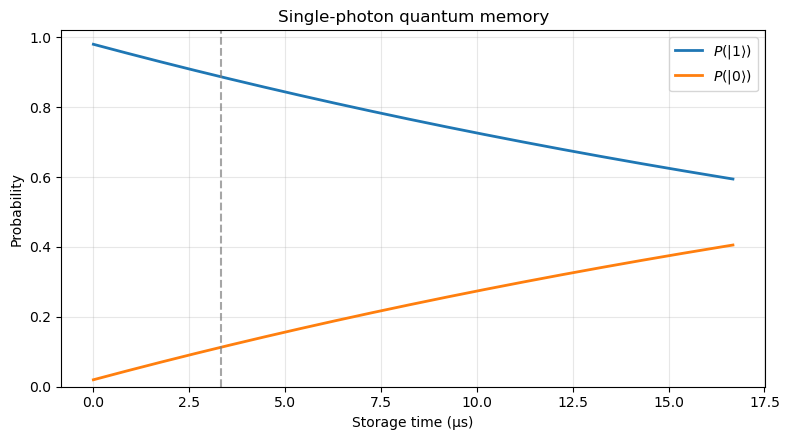

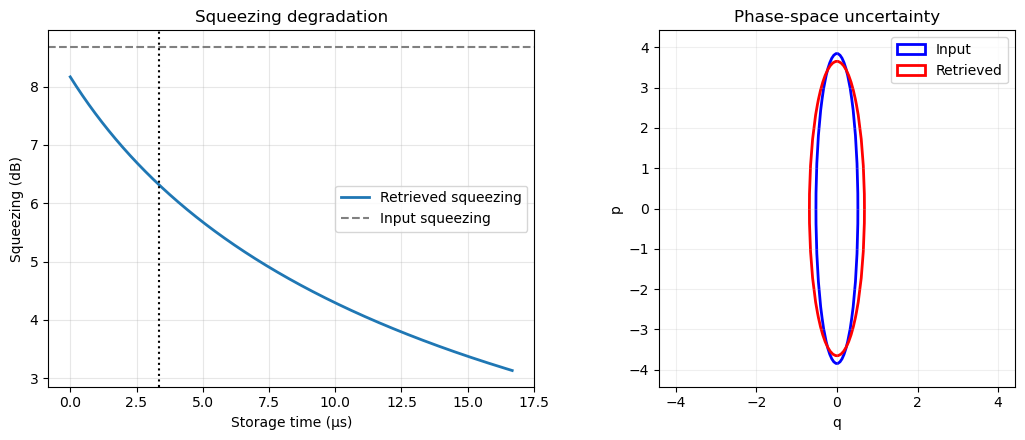

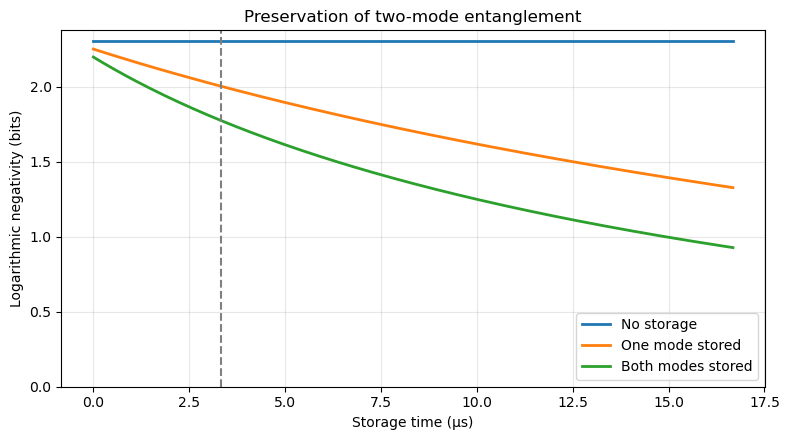

In [5]:

# ============================================================
# CELL 5 — VISUALIZATION FUNCTIONS
# Requires Cells 1–4
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse


def plot_fock_memory(memory, Nmax=5000, N_selected=1000):
    """Single-photon survival and vacuum probability."""

    N = np.arange(Nmax + 1)
    eta = memory.efficiency(N)

    fig, ax = plt.subplots(figsize=(8, 4.5))

    ax.plot(
        memory.storage_time_us(N),
        eta,
        label=r"$P(|1\rangle)$",
        linewidth=2
    )

    ax.plot(
        memory.storage_time_us(N),
        1 - eta,
        label=r"$P(|0\rangle)$",
        linewidth=2
    )

    ax.axvline(
        memory.storage_time_us(N_selected),
        color="gray",
        linestyle="--",
        alpha=0.7
    )

    ax.set_xlabel("Storage time (µs)")
    ax.set_ylabel("Probability")
    ax.set_ylim(0, 1.02)
    ax.set_title("Single-photon quantum memory")
    ax.legend()
    ax.grid(alpha=0.3)

    fig.tight_layout()

    return fig


def covariance_ellipse(ax, V, color, label,
                       scale=2.0, linestyle="-"):
    """
    Draw an uncertainty ellipse from a 2x2 covariance.

    scale = number of covariance standard deviations.
    """
    eigenvalues, eigenvectors = np.linalg.eigh(V)

    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    angle = np.degrees(
        np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0])
    )

    width, height = 2 * scale * np.sqrt(eigenvalues)

    ellipse = Ellipse(
        (0, 0),
        width=width,
        height=height,
        angle=angle,
        fill=False,
        edgecolor=color,
        linewidth=2,
        linestyle=linestyle,
        label=label
    )

    ax.add_patch(ellipse)


def plot_squeezed_memory(memory, Nmax=5000,
                        N_selected=1000, r=1.0):
    """Squeezing loss and phase-space uncertainty ellipses."""

    N = np.arange(Nmax + 1)

    eta = memory.efficiency(N)

    input_sq_db = 20 * r / np.log(10)

    output_sq_db = -10 * np.log10(
        eta * np.exp(-2 * r) + (1 - eta)
    )

    d = squeezed_memory_output(memory, N_selected, r)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    ax = axes[0]

    ax.plot(
        memory.storage_time_us(N),
        output_sq_db,
        linewidth=2,
        label="Retrieved squeezing"
    )

    ax.axhline(
        input_sq_db,
        linestyle="--",
        color="gray",
        label="Input squeezing"
    )

    ax.axvline(
        memory.storage_time_us(N_selected),
        linestyle=":",
        color="black"
    )

    ax.set_xlabel("Storage time (µs)")
    ax.set_ylabel("Squeezing (dB)")
    ax.set_title("Squeezing degradation")
    ax.legend()
    ax.grid(alpha=0.3)

    ax = axes[1]

    covariance_ellipse(
        ax, d["Vin"], "blue", "Input"
    )

    covariance_ellipse(
        ax, d["Vout"], "red", "Retrieved"
    )

    limit = 2.3 * np.sqrt(
        np.max(np.linalg.eigvalsh(d["Vin"]))
    )

    ax.set_xlim(-limit, limit)
    ax.set_ylim(-limit, limit)
    ax.set_aspect("equal")
    ax.set_xlabel("q")
    ax.set_ylabel("p")
    ax.set_title("Phase-space uncertainty")
    ax.legend()
    ax.grid(alpha=0.2)

    fig.tight_layout()

    return fig


def plot_entanglement_memory(memory, Nmax=5000,
                            N_selected=1000, r=0.8):
    """Log negativity for one-mode and two-mode storage."""

    N_values = np.linspace(0, Nmax, 180, dtype=int)

    curves = {}

    for stored in ("none", "one", "both"):
        curves[stored] = [
            entanglement_diagnostics(
                memory, int(N), r, stored
            )["log_negativity"]
            for N in N_values
        ]

    fig, ax = plt.subplots(figsize=(8, 4.5))

    for stored, label in (
        ("none", "No storage"),
        ("one", "One mode stored"),
        ("both", "Both modes stored")
    ):
        ax.plot(
            memory.storage_time_us(N_values),
            curves[stored],
            linewidth=2,
            label=label
        )

    ax.axvline(
        memory.storage_time_us(N_selected),
        color="gray",
        linestyle="--"
    )

    ax.set_xlabel("Storage time (µs)")
    ax.set_ylabel("Logarithmic negativity (bits)")
    ax.set_title("Preservation of two-mode entanglement")
    ax.legend()
    ax.grid(alpha=0.3)
    ax.set_ylim(bottom=0)

    fig.tight_layout()

    return fig


# ------------------------------------------------------------
# VISUALIZATION TESTS
# ------------------------------------------------------------

def test_visualizations():

    memory = MirrorMemory(
        R=0.9999,
        eta_in=0.99,
        eta_out=0.99,
        path_m=1.0
    )

    figures = [
        plot_fock_memory(memory),
        plot_squeezed_memory(memory, r=1.0),
        plot_entanglement_memory(memory, r=0.8)
    ]

    assert len(figures) == 3

    for fig in figures:
        assert isinstance(fig, plt.Figure)
        assert len(fig.axes) >= 1

    print("All visualization tests passed.")

    plt.show()


test_visualizations()

In [6]:

# ============================================================
# CELL 6A — STORAGE GEOMETRY AND TIMING
# Requires MirrorMemory from Cell 1
# ============================================================

import numpy as np


def reflections_for_time(memory, requested_us):
    """
    Minimum number of reflections giving at least the
    requested propagation time.

    Simplified fixed-distance-per-reflection model.
    """
    if not np.isfinite(requested_us) or requested_us < 0:
        raise ValueError("Storage time must be finite and >= 0")

    N = int(np.ceil(
        (requested_us * 1e-6 * C_LIGHT)
        / memory.path_m - 1e-12
    ))
    return max(0, N)


def memory_geometry_diagnostics(memory, requested_us):
    N = reflections_for_time(memory, requested_us)

    return {
        "requested_us": requested_us,
        "N": N,
        "actual_us": float(memory.storage_time_us(N)),
        "optical_path_m": N * memory.path_m,
        "eta": float(memory.efficiency(N)),
    }


# ------------------------------------------------------------
# Unit tests
# ------------------------------------------------------------

def test_storage_geometry():

    mem = MirrorMemory(
        R=0.9999,
        eta_in=1.0,
        eta_out=1.0,
        path_m=1.0
    )

    assert reflections_for_time(mem, 0.0) == 0

    # One metre of optical travel corresponds to one reflection
    t1 = 1.0 / C_LIGHT * 1e6
    assert reflections_for_time(mem, t1) == 1

    # More optical distance per reflection means fewer reflections
    short = MirrorMemory(R=0.9999, path_m=0.5)
    long = MirrorMemory(R=0.9999, path_m=2.0)

    d_short = memory_geometry_diagnostics(short, 3.0)
    d_long = memory_geometry_diagnostics(long, 3.0)

    assert d_short["N"] > d_long["N"]
    assert d_long["eta"] > d_short["eta"]

    # Achieved storage time is at least requested
    assert d_short["actual_us"] >= 3.0 - 1e-12
    assert d_long["actual_us"] >= 3.0 - 1e-12

    # Error handling
    try:
        reflections_for_time(mem, -1.0)
        raise AssertionError("Negative time accepted")
    except ValueError:
        pass

    print("All storage-geometry tests passed.")


test_storage_geometry()

All storage-geometry tests passed.


In [7]:

# ============================================================
# CELL 6B — INTERACTIVE GEOMETRY EXPLORER
# Requires Cell 6A
# ============================================================

import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt

path_slider = widgets.FloatSlider(
    value=1.0, min=0.1, max=5.0, step=0.1,
    description="Path (m):",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="450px")
)

time_slider = widgets.FloatSlider(
    value=3.0, min=0.0, max=15.0, step=0.1,
    description="Storage time (µs):",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="450px")
)

R_slider = widgets.FloatSlider(
    value=0.9999, min=0.99, max=1.0, step=0.0001,
    readout_format=".4f",
    description="Reflectivity:",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="450px")
)

geometry_output = widgets.Output()


def update_geometry(change=None):

    mem = MirrorMemory(
        R=R_slider.value,
        eta_in=0.99,
        eta_out=0.99,
        path_m=path_slider.value
    )

    d = memory_geometry_diagnostics(
        mem, time_slider.value
    )

    with geometry_output:
        clear_output(wait=True)

        print(f"Required reflections : {d['N']}")
        print(f"Actual storage time  : {d['actual_us']:.4f} µs")
        print(f"Total optical path   : {d['optical_path_m']:.2f} m")
        print(f"Memory efficiency    : {d['eta']:.6f}")

        lengths = np.linspace(0.1, 5.0, 200)
        efficiencies = []

        for L in lengths:
            m = MirrorMemory(
                R=R_slider.value,
                eta_in=0.99,
                eta_out=0.99,
                path_m=float(L)
            )
            efficiencies.append(
                memory_geometry_diagnostics(
                    m, time_slider.value
                )["eta"]
            )

        fig, ax = plt.subplots(figsize=(8, 4))

        ax.plot(lengths, efficiencies, linewidth=2)

        ax.axvline(
            path_slider.value,
            color="gray",
            linestyle="--",
            label="Selected optical distance"
        )

        ax.scatter(
            [path_slider.value],
            [d["eta"]],
            s=55,
            zorder=5
        )

        ax.set_xlabel("Optical distance per reflection (m)")
        ax.set_ylabel("Memory transmissivity")
        ax.set_ylim(0, 1.02)
        ax.set_title(
            f"Fixed requested storage time: {time_slider.value:.1f} µs"
        )
        ax.grid(alpha=0.3)
        ax.legend()

        plt.show()
        plt.close(fig)


for slider in (path_slider, time_slider, R_slider):
    slider.observe(update_geometry, names="value")

display(
    widgets.VBox([
        widgets.HTML("<h3>Optical Memory: Geometry and Storage</h3>"),
        path_slider,
        time_slider,
        R_slider,
        geometry_output
    ])
)

update_geometry()

In [12]:

# ============================================================
# CELL 7E — CLEAN INTEGRATED QUANTUM MEMORY UI
#
# Requires verified physics and plotting functions:
# Cells 1–5 and reflections_for_time() from Cell 6A.
#
# Fresh widgets, one observer per control, no hidden widgets.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

# ------------------------------------------------------------
# 1. FRESH CONTROLS
# ------------------------------------------------------------

style = {"description_width": "180px"}
layout = widgets.Layout(width="520px")

qm_state = widgets.Dropdown(
    options=[
        ("Single-photon Fock |1>", "fock"),
        ("Squeezed vacuum", "squeezed"),
        ("Two-mode squeezed vacuum", "entangled")
    ],
    value="fock",
    description="Quantum state:",
    style=style,
    layout=layout
)

qm_R = widgets.FloatSlider(
    value=0.9999, min=0.99, max=1.0,
    step=0.0001, readout_format=".4f",
    description="Mirror reflectivity:",
    continuous_update=False,
    style=style, layout=layout
)

qm_in = widgets.FloatSlider(
    value=0.99, min=0.80, max=1.0,
    step=0.005, readout_format=".3f",
    description="Injection efficiency:",
    continuous_update=False,
    style=style, layout=layout
)

qm_out = widgets.FloatSlider(
    value=0.99, min=0.80, max=1.0,
    step=0.005, readout_format=".3f",
    description="Extraction efficiency:",
    continuous_update=False,
    style=style, layout=layout
)

qm_length = widgets.FloatSlider(
    value=1.0, min=0.1, max=5.0,
    step=0.1,
    description="Path per reflection (m):",
    continuous_update=False,
    style=style, layout=layout
)

qm_time = widgets.FloatSlider(
    value=3.0, min=0.0, max=15.0,
    step=0.1,
    description="Storage time (µs):",
    continuous_update=False,
    style=style, layout=layout
)

qm_phase = widgets.FloatSlider(
    value=0.0, min=-0.1, max=0.1,
    step=0.005,
    description="Phase per reflection:",
    continuous_update=False,
    style=style, layout=layout
)

qm_squeeze = widgets.FloatSlider(
    value=10.0, min=0.0, max=15.0,
    step=0.5,
    description="Input squeezing (dB):",
    continuous_update=False,
    style=style, layout=layout
)

qm_stored = widgets.Dropdown(
    options=[
        ("One mode stored", "one"),
        ("Both modes stored", "both")
    ],
    value="both",
    description="Entanglement storage:",
    style=style, layout=layout
)

qm_output = widgets.Output()


# ------------------------------------------------------------
# 2. SINGLE UPDATE FUNCTION
# ------------------------------------------------------------

def qm_update(change=None):

    memory = MirrorMemory(
        R=qm_R.value,
        eta_in=qm_in.value,
        eta_out=qm_out.value,
        path_m=qm_length.value,
        phase_rad=qm_phase.value
    )

    N = reflections_for_time(memory, qm_time.value)
    eta = float(memory.efficiency(N))
    actual_time = float(memory.storage_time_us(N))
    r = qm_squeeze.value * np.log(10.0) / 20.0

    Nmax = max(1000, int(1.5 * N) + 1)

    with qm_output:
        clear_output(wait=True)

        print("QUANTUM OPTICAL MIRROR MEMORY")
        print("-" * 55)
        print(f"Input state          : {qm_state.label}")
        print(f"Reflections          : {N:,}")
        print(f"Storage time         : {actual_time:.4f} µs")
        print(f"Total optical path   : {N * memory.path_m:.2f} m")
        print(f"Memory efficiency    : {eta:.6f}")
        print(f"Photon loss          : {1-eta:.6f}")
        print()

        if qm_state.value == "fock":

            d = fock_diagnostics(memory, N)

            print(f"Photon probability   : {d['p_photon']:.6f}")
            print(f"Vacuum probability   : {d['p_vacuum']:.6f}")
            print(f"Conditional fidelity : "
                  f"{d['conditional_fidelity']:.6f}")
            print(f"Output purity        : {d['purity']:.6f}")

            fig = plot_fock_memory(
                memory, Nmax=Nmax, N_selected=N
            )

        elif qm_state.value == "squeezed":

            d = squeezed_memory_output(memory, N, r)

            print(f"Input squeezing      : "
                  f"{d['input_squeezing_db']:.3f} dB")
            print(f"Output squeezing     : "
                  f"{d['output_squeezing_db']:.3f} dB")
            print(f"Output purity        : "
                  f"{d['output_purity']:.6f}")

            fig = plot_squeezed_memory(
                memory, Nmax=Nmax,
                N_selected=N, r=r
            )

        else:

            d = entanglement_diagnostics(
                memory, N, r, qm_stored.value
            )

            print(f"Modes stored         : {qm_stored.value}")
            print(f"Log negativity       : "
                  f"{d['log_negativity']:.6f}")
            print(f"Output purity        : "
                  f"{d['purity']:.6f}")
            print(f"EPR variance sum     : "
                  f"{d['epr_sum']:.6f}")

            fig = plot_entanglement_memory(
                memory, Nmax=Nmax,
                N_selected=N, r=r
            )

        plt.show()
        plt.close(fig)


# ------------------------------------------------------------
# 3. DISPLAY ALL CONTROLS — NOTHING HIDDEN
# ------------------------------------------------------------

qm_controls = widgets.VBox([
    widgets.HTML("<h2>Quantum Optical Mirror Memory Simulator</h2>"),
    widgets.HTML("<h3>Quantum state</h3>"),
    qm_state,
    qm_squeeze,
    qm_stored,

    widgets.HTML("<h3>Optical memory</h3>"),
    qm_R,
    qm_in,
    qm_out,
    qm_length,
    qm_phase,

    widgets.HTML("<h3>Storage</h3>"),
    qm_time,

    widgets.HTML(
        "<p><small>Model: passive multipass optical memory "
        "with pure loss and deterministic phase rotation. "
        "Path per reflection is an effective optical distance, "
        "not the physical device footprint.</small></p>"
    )
])

qm_interface = widgets.VBox([qm_controls, qm_output])

# ------------------------------------------------------------
# 4. REGISTER CALLBACKS ONCE
# ------------------------------------------------------------

for control in (
    qm_state, qm_R, qm_in, qm_out,
    qm_length, qm_time, qm_phase,
    qm_squeeze, qm_stored
):
    control.observe(qm_update, names="value")

display(qm_interface)
qm_update()
